In [3]:
import os
import pandas as pd
import matplotlib.pyplot as plt
from cluster_weather_years.constants import COUNTRIES, BASE_OUTPUT


In [4]:
FNAME_PROD_DEMAND = "dataframes/df_prod_demand_daily_multi_country_WRONG_DEMAND.csv"
df = pd.read_csv(os.path.join(BASE_OUTPUT, FNAME_PROD_DEMAND))

In [6]:
df.head()

,Unnamed: 0,model,Date,Hydrological_year,AL_OFF_prod,AL_ON_prod,AL_SOLAR_prod,AL_Demand,AL_Residual_load,AT_OFF_prod,...,UK_ON_prod,UK_SOLAR_prod,UK_Demand,UK_Residual_load,TR_OFF_prod,TR_ON_prod,TR_SOLAR_prod,TR_Demand,TR_Residual_load,Calendar_year
0,0,awi_cm_1_1_mr,2015-01-01,2014,NaN,NaN,0.503594,27.084125,NaN,NaN,...,145.998225,11.890266,987.836500,555.869585,NaN,163.409249,47.82400,1303.540024,NaN,2015
1,1,awi_cm_1_1_mr,2015-01-02,2014,NaN,NaN,0.648221,26.422378,NaN,NaN,...,317.147952,15.038664,977.375060,-153.047533,NaN,213.561368,35.46448,1268.879415,NaN,2015
2,2,awi_cm_1_1_mr,2015-01-03,2014,NaN,NaN,0.462644,26.568488,NaN,NaN,...,174.120316,11.769530,1011.121897,139.738136,NaN,75.242703,27.76320,1273.530816,NaN,2015
3,3,awi_cm_1_1_mr,2015-01-04,2014,NaN,NaN,1.188649,26.203875,NaN,NaN,...,91.378455,10.396330,1047.592396,657.371422,NaN,159.222628,28.25648,1289.075741,NaN,2015
4,4,awi_cm_1_1_mr,2015-01-05,2014,NaN,NaN,0.803691,27.823299,NaN,NaN,...,371.076203,1.769365,1028.780721,-4.018904,NaN,313.276389,27.70176,1284.142527,NaN,2015


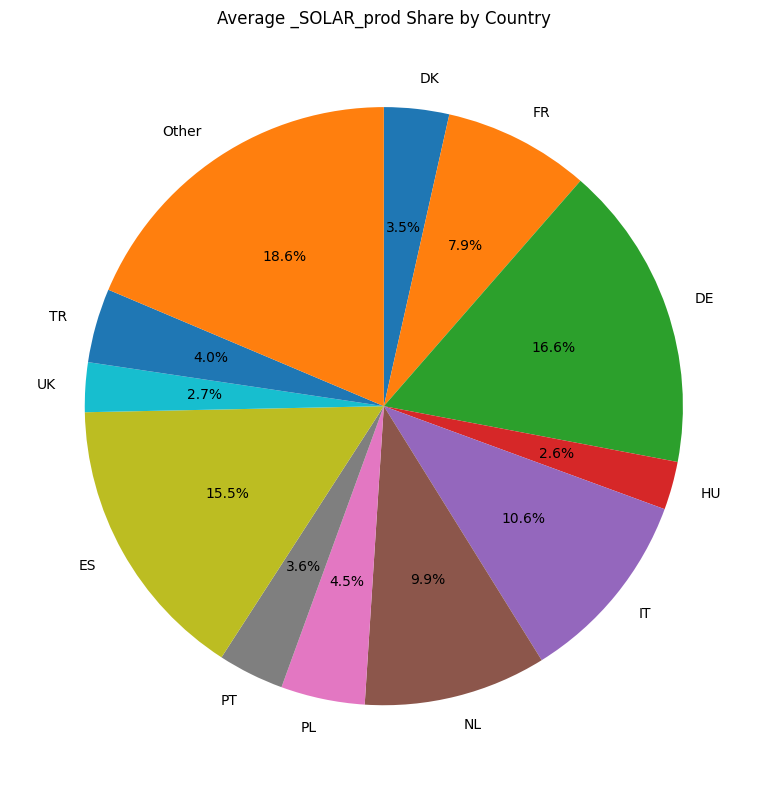

Countries in 'Other': ['AL', 'AT', 'BE', 'BA', 'BG', 'HR', 'CZ', 'EE', 'FI', 'IE', 'LV', 'LT', 'LU', 'MT', 'ME', 'MK', 'NO', 'RO', 'RS', 'SK', 'SI', 'SE', 'CH']


In [ ]:
def plot_prod_shares(
    df_prod_demand: pd.DataFrame, var, threshold_pct: float = 2.5
) -> list[str]:
    """
    Plot a pie chart of mean var production shares per country.
    Countries with shares below `threshold_pct` are grouped into "Other".
    """
    solar_cols = [c for c in df_prod_demand.columns if c.endswith(var)]
    mean_solar = df_prod_demand[solar_cols].mean()

    mean_solar.index = mean_solar.index.str.replace(var, "", regex=False)

    shares_pct = mean_solar / mean_solar.sum() * 100.0

    mask_major = shares_pct >= threshold_pct
    major = mean_solar[mask_major]
    other_total = mean_solar[~mask_major].sum()

    values = list(major.values) + [other_total]
    labels = list(major.index) + ["Other"]

    plt.figure(figsize=(8, 8))
    plt.pie(values, labels=labels, autopct="%.1f%%", startangle=90, counterclock=False)
    plt.title(f"Average {var} Share by Country")
    plt.tight_layout()
    plt.show()

    other_countries = list(mean_solar.index[~mask_major])
    return other_countries


other_countries = plot_prod_shares(df, "_SOLAR_prod")
print("Countries in 'Other':", other_countries)


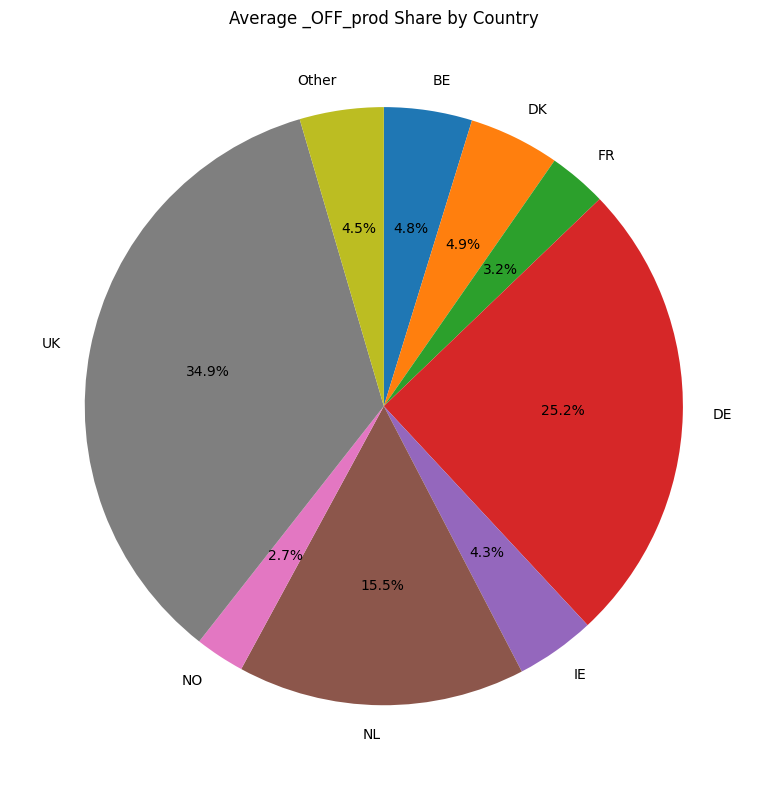

Countries in 'Other': ['AL', 'AT', 'BA', 'BG', 'HR', 'CZ', 'EE', 'FI', 'HU', 'IT', 'LV', 'LT', 'LU', 'MT', 'ME', 'MK', 'PL', 'PT', 'RO', 'RS', 'SK', 'SI', 'ES', 'SE', 'CH', 'TR']


In [14]:
other_countries = plot_prod_shares(df, "_OFF_prod")
print("Countries in 'Other':", other_countries)

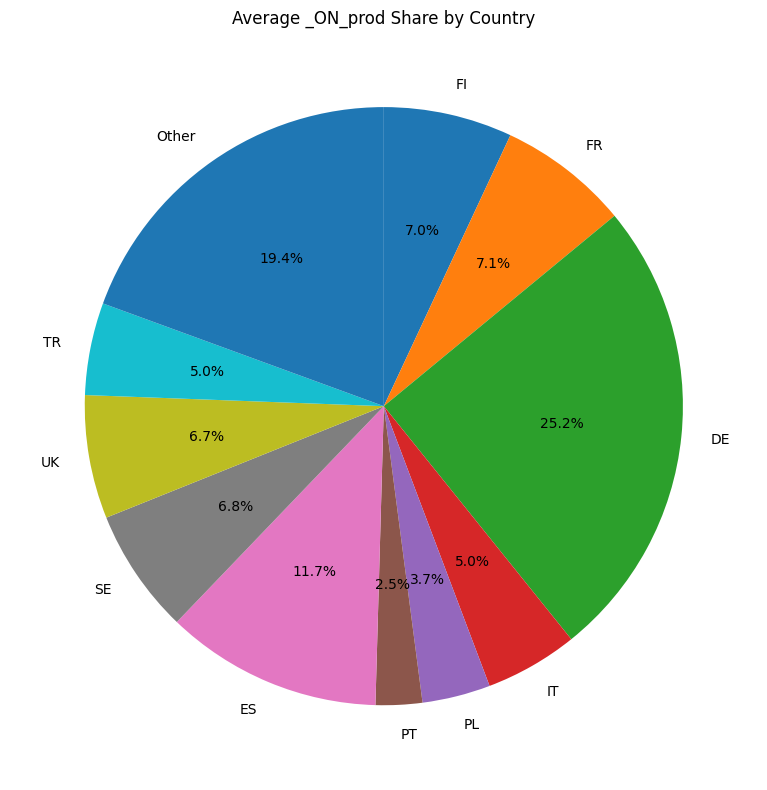

Countries in 'Other': ['AL', 'AT', 'BE', 'BA', 'BG', 'HR', 'CZ', 'DK', 'EE', 'HU', 'IE', 'LV', 'LT', 'LU', 'MT', 'ME', 'MK', 'NL', 'NO', 'RO', 'RS', 'SK', 'SI', 'CH']


In [16]:
other_countries = plot_prod_shares(df, "_ON_prod")
print("Countries in 'Other':", other_countries)